In [2]:
%pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 3.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154569 sha256=55f09e1ea50dbc8dfadb510575bbeb3bac9ead5875decb4744b710624aecb288
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [3]:
# M24CA1L306 Data Science Lab - Lab Exercise #22
# Student: Abhinav | MAC25MCA-2002 | S3 MCA (2025-27)
# Dataset: <PLACEHOLDER - replace with Heart_Disease.csv filename>
#          PLACEHOLDER: adjust target/column names below to match your file
# Task: EDA + K-Medoids clustering on Heart Disease dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score


In [4]:

# ─────────────────────────────────────────────
# Load dataset
# ─────────────────────────────────────────────
df = pd.read_csv("/content/Heart_Disease.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:\n", df.head())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDescriptive statistics:\n", df.describe())


Shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

First 5 rows:
    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Data types:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
s

In [5]:

# PLACEHOLDER: drop non-numeric or ID columns if needed
# df.drop(columns=["id"], inplace=True, errors="ignore")

# ─────────────────────────────────────────────
# (i) EDA
# ─────────────────────────────────────────────
print("\nCorrelation matrix:\n", df.corr(numeric_only=True))



Correlation matrix:
                age       sex        cp  trestbps      chol       fbs  \
age       1.000000 -0.103240 -0.071966  0.271121  0.219823  0.121243   
sex      -0.103240  1.000000 -0.041119 -0.078974 -0.198258  0.027200   
cp       -0.071966 -0.041119  1.000000  0.038177 -0.081641  0.079294   
trestbps  0.271121 -0.078974  0.038177  1.000000  0.127977  0.181767   
chol      0.219823 -0.198258 -0.081641  0.127977  1.000000  0.026917   
fbs       0.121243  0.027200  0.079294  0.181767  0.026917  1.000000   
restecg  -0.132696 -0.055117  0.043581 -0.123794 -0.147410 -0.104051   
thalach  -0.390227 -0.049365  0.306839 -0.039264 -0.021772 -0.008866   
exang     0.088163  0.139157 -0.401513  0.061197  0.067382  0.049261   
oldpeak   0.208137  0.084687 -0.174733  0.187434  0.064880  0.010859   
slope    -0.169105 -0.026666  0.131633 -0.120445 -0.014248 -0.061902   
ca        0.271551  0.111729 -0.176206  0.104554  0.074259  0.137156   
thal      0.072297  0.198424 -0.163341  0.

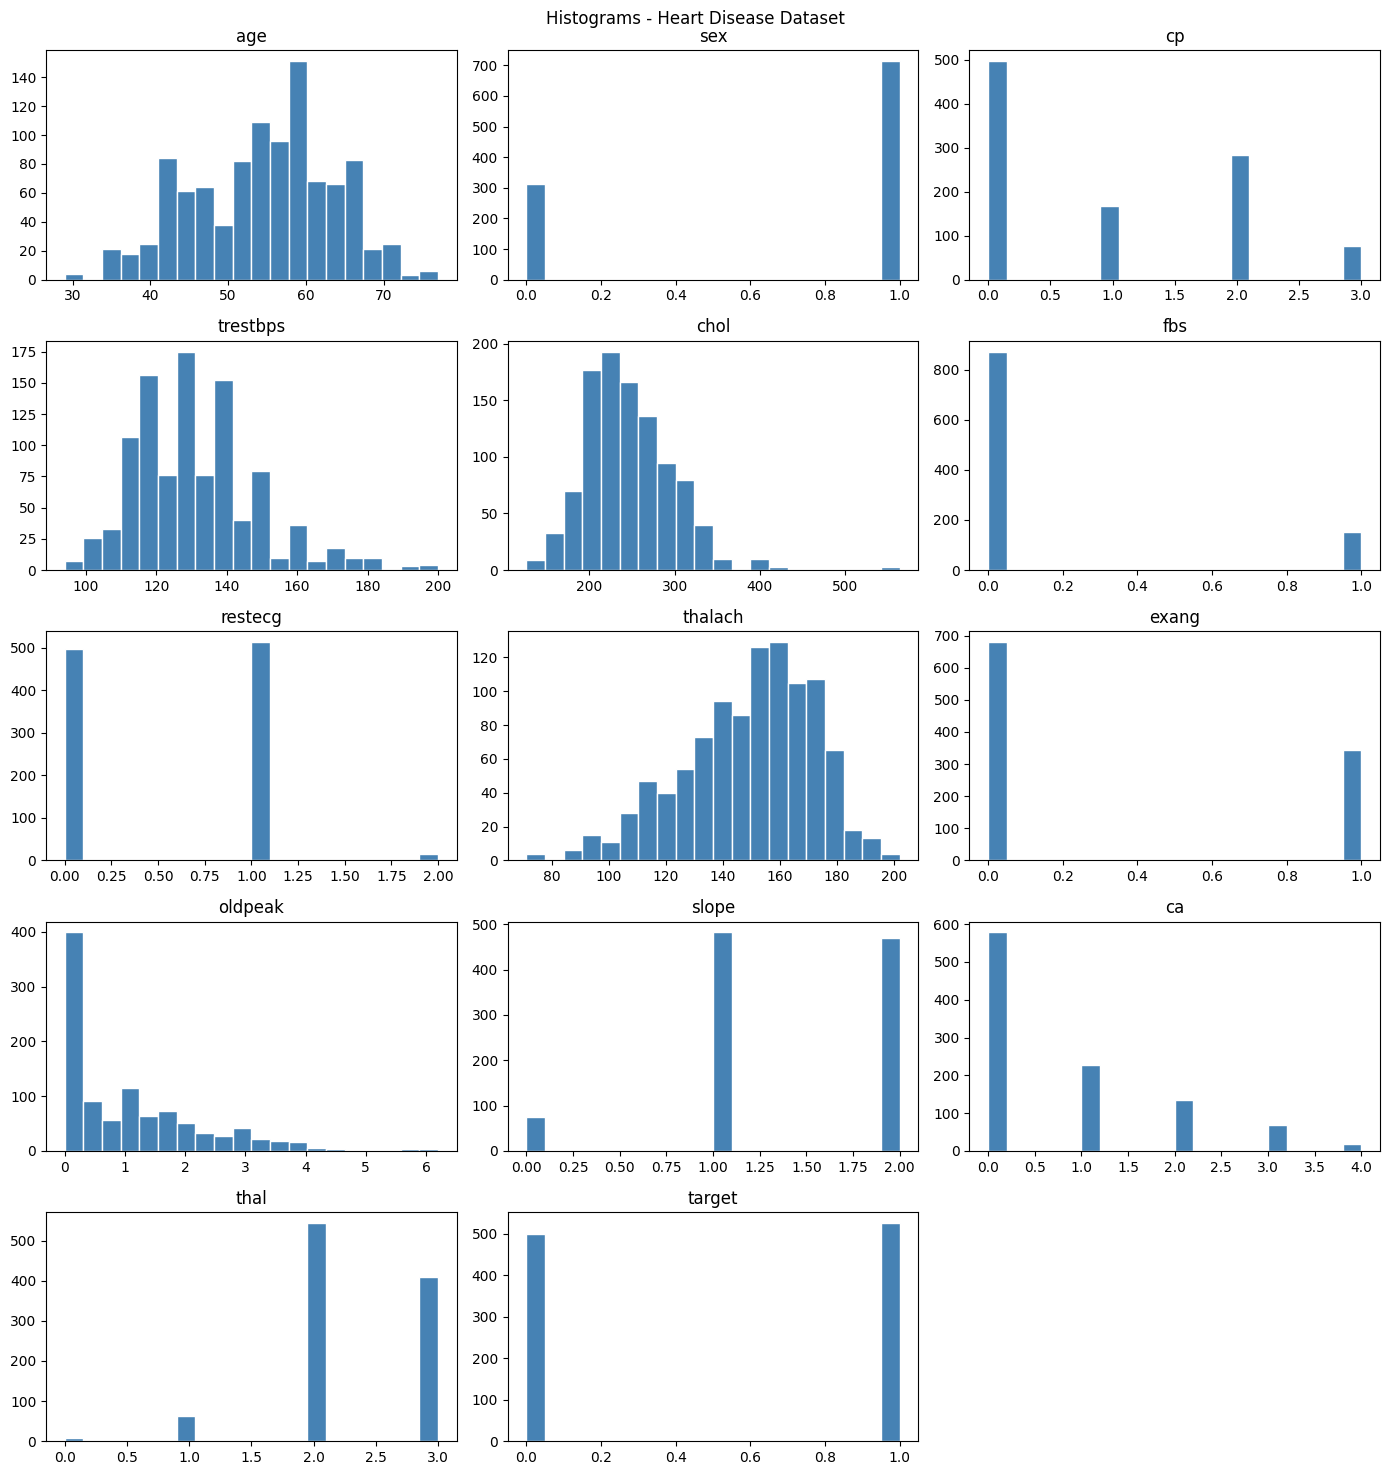

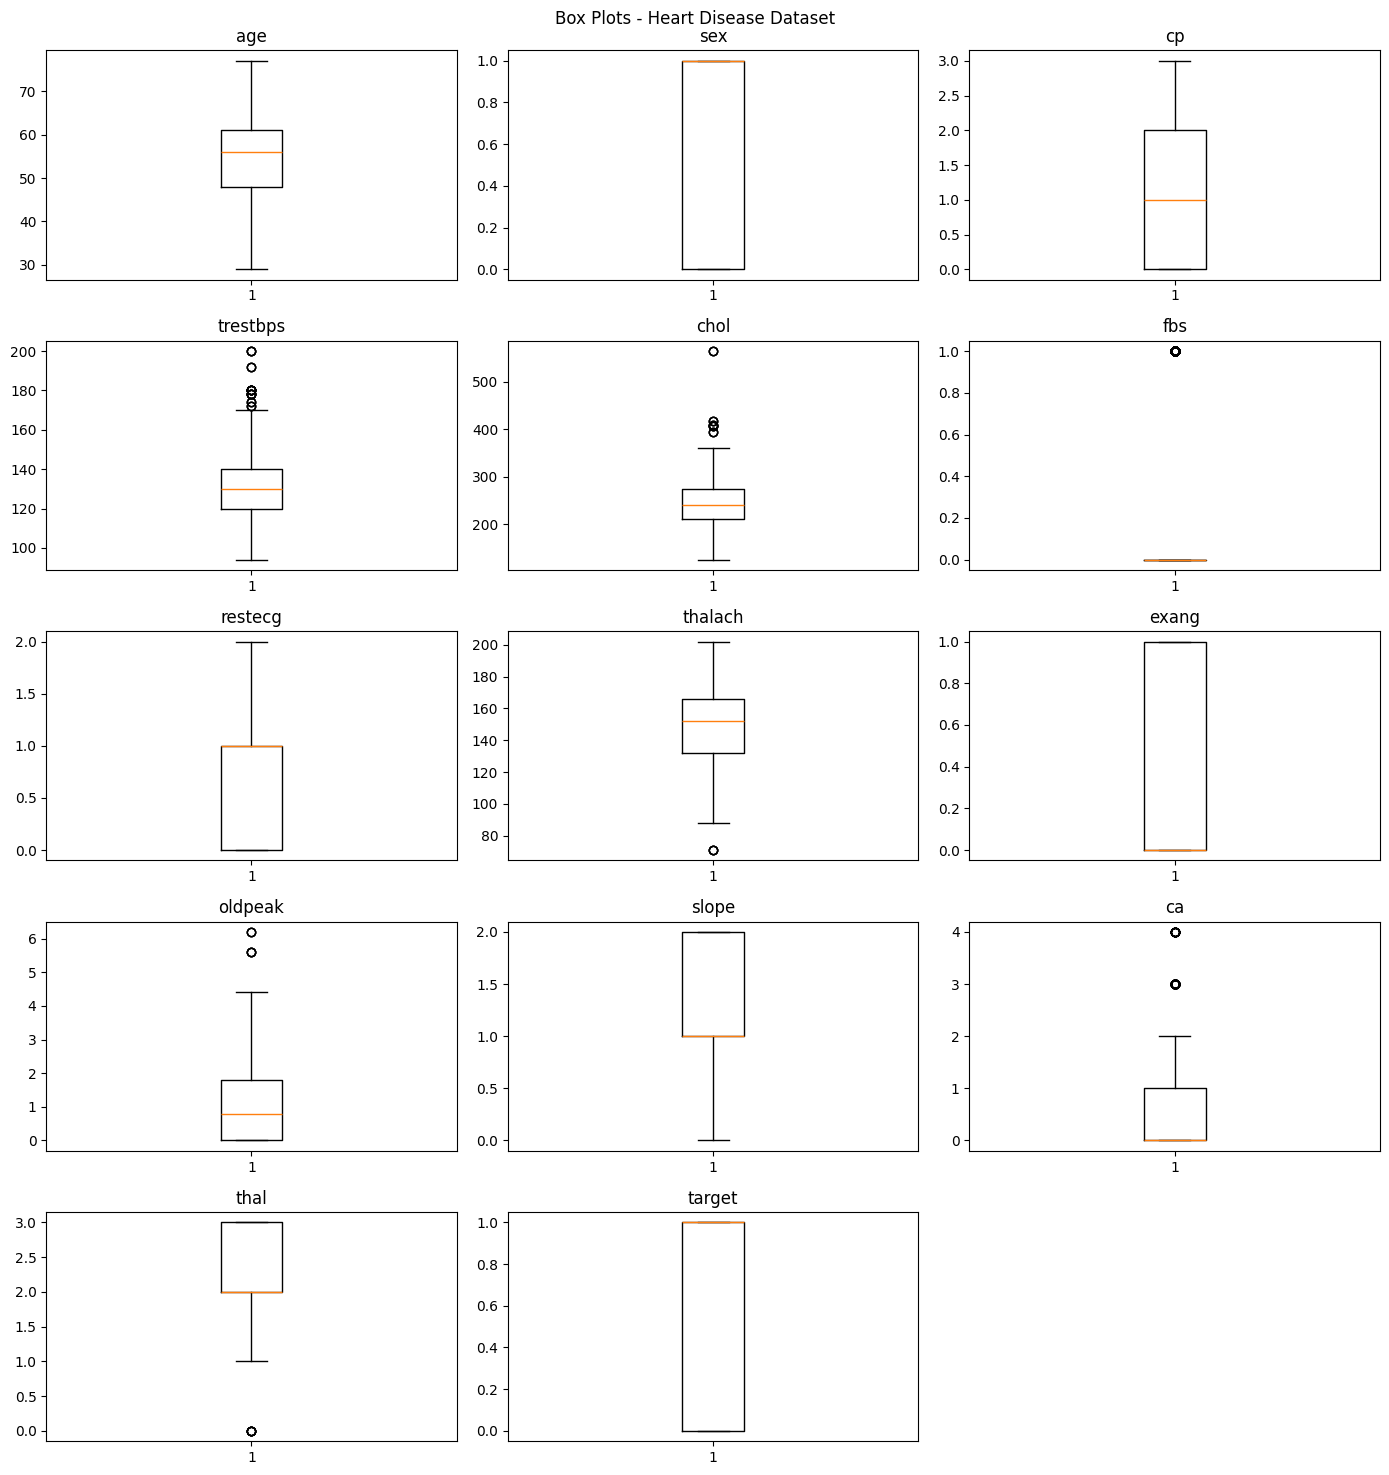

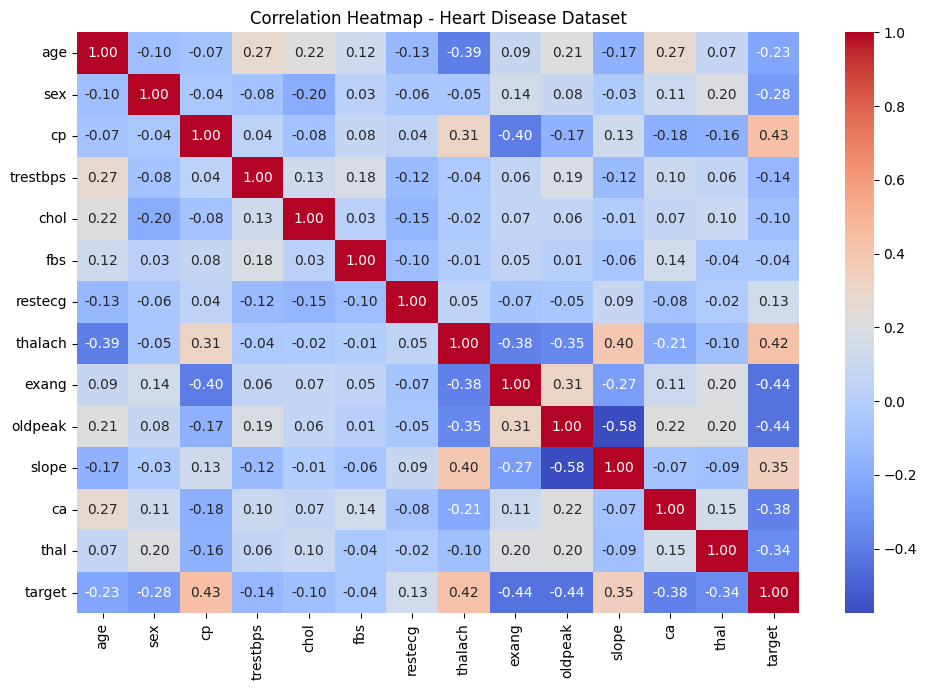

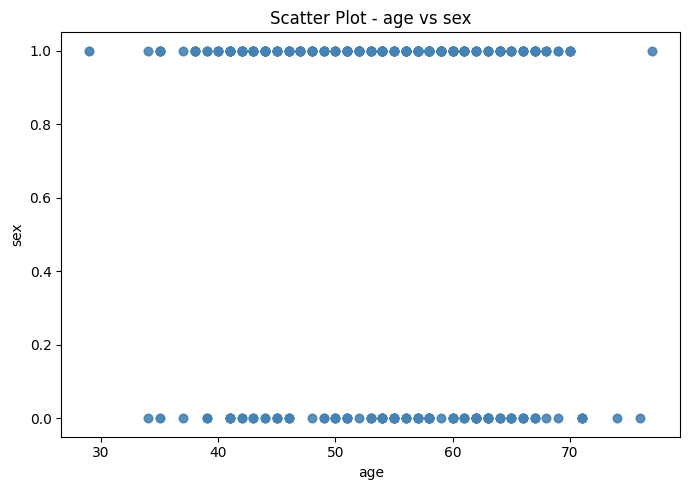

In [7]:

# ─────────────────────────────────────────────
# (ii) EDA Visualizations
# ─────────────────────────────────────────────
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
n = len(numeric_cols)

# Histogram
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3 * ((n + 2) // 3)))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(df[col].dropna(), bins=20, color="steelblue", edgecolor="white")
    ax.set_title(col)
for ax in axes.flatten()[n:]:
    ax.set_visible(False)
plt.suptitle("Histograms - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_histogram.png", dpi=100)
plt.show()

# Box plot
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3 * ((n + 2) // 3)))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
for ax in axes.flatten()[n:]:
    ax.set_visible(False)
plt.suptitle("Box Plots - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_boxplot.png", dpi=100)
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_heatmap.png", dpi=100)
plt.show()

# Scatter plot - PLACEHOLDER: replace with two relevant columns
col1 = numeric_cols[0]
col2 = numeric_cols[1]
plt.figure(figsize=(7, 5))
plt.scatter(df[col1], df[col2], alpha=0.5, color="steelblue")
plt.xlabel(col1)
plt.ylabel(col2)
plt.title(f"Scatter Plot - {col1} vs {col2}")
plt.tight_layout()
plt.savefig("lab22_scatter.png", dpi=100)
plt.show()



k  | Silhouette Score | Davies-Bouldin Index
---------------------------------------------
k=2 | -0.1872           | 1.6021


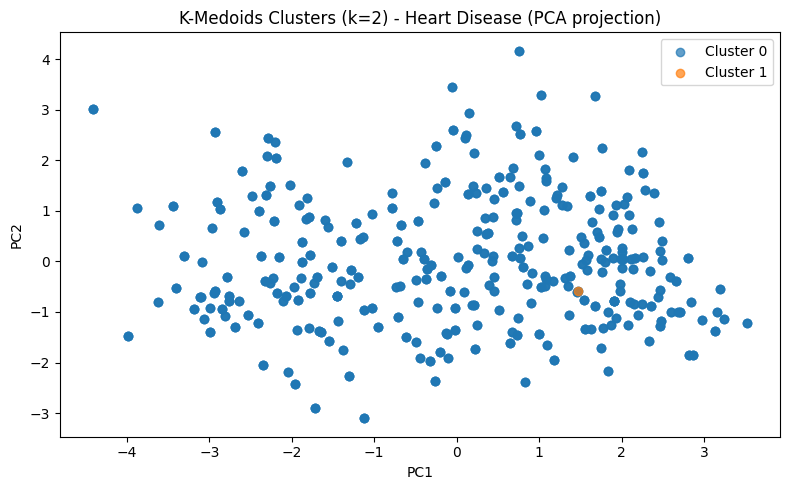

k=3 | -0.1863           | 1.6011


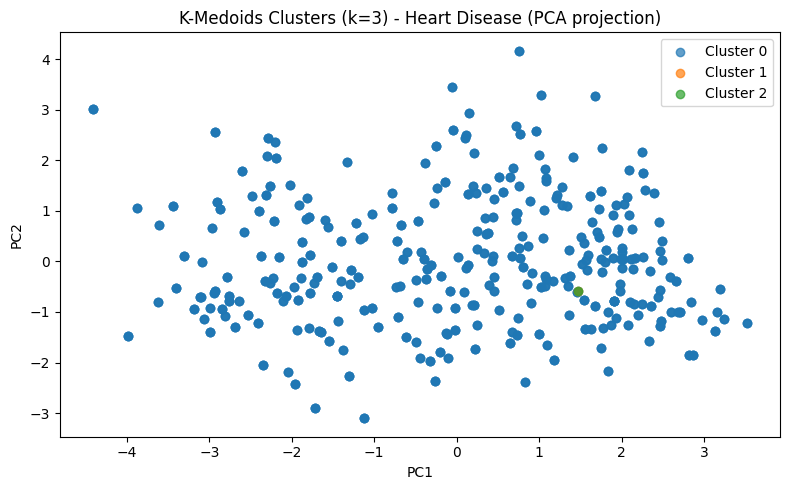

In [9]:

# ─────────────────────────────────────────────
# (iii) K-Medoids with k=2 and k=3
# ─────────────────────────────────────────────
X = df[numeric_cols].dropna().values
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca   = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nk  | Silhouette Score | Davies-Bouldin Index")
print("-" * 45)

for k in [2, 3]:
    km     = KMedoids(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    sil    = silhouette_score(X_scaled, labels)
    db     = davies_bouldin_score(X_scaled, labels)
    print(f"k={k} | {sil:.4f}           | {db:.4f}")

    plt.figure(figsize=(8, 5))
    for cluster in range(k):
        mask = labels == cluster
        plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                    label=f"Cluster {cluster}", alpha=0.7)
    plt.title(f"K-Medoids Clusters (k={k}) - Heart Disease (PCA projection)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"lab22_clusters_k{k}.png", dpi=100)
    plt.show()


In [10]:

# ─────────────────────────────────────────────
# (iv) Silhouette Score and Davies-Bouldin Index summary
# ─────────────────────────────────────────────
print("\nFinal evaluation (repeated for clarity):")
for k in [2, 3]:
    km     = KMedoids(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    sil    = silhouette_score(X_scaled, labels)
    db     = davies_bouldin_score(X_scaled, labels)
    print(f"k={k}  Silhouette Score: {sil:.4f}  Davies-Bouldin Index: {db:.4f}")

print("\nAll tasks complete. Plots saved.")


Final evaluation (repeated for clarity):
k=2  Silhouette Score: -0.1872  Davies-Bouldin Index: 1.6021
k=3  Silhouette Score: -0.1863  Davies-Bouldin Index: 1.6011

All tasks complete. Plots saved.
